# Projeto Métodos Numéricos (2º GQ) — Problema 2: Investigação de Degradação de Desempenho em Servidores

**Integrantes do Grupo:**
- **Carlos Gabryell:** Engenharia de Dados (`dados.py`)
- **Diego Kauã:** Interpolação Polinomial de Lagrange (`lagrange.py`)
- **Matheus:** Interpolação Polinomial de Newton (`newton.py`)
- **Lucas Vinícius:** Cálculos, Verificação de Limite e Análise de Precisão (`analise.py` — Itens a e b)
- **Moisés Freire:** Visualização Gráfica e Diagnóstico de Infraestrutura (`graficos.py` — Itens c e d)
- **Henry Lima:** Empacotamento (`pyproject.toml`), Documentação (`README.md`) e Consolidação

---

## 1. Contextualização e Enunciado do Problema

Uma empresa de tecnologia realiza o monitoramento da temperatura dos processadores de três servidores de seu data center (`SRV-01`, `SRV-02` e `SRV-03`). As medições são coletadas em intervalos de uma hora durante um período de 10 horas (14:00 às 23:00) e armazenadas no arquivo `temperaturas.csv`.

Durante o monitoramento, ocorreram episódios de degradação de desempenho registrados no arquivo `incidentes.log` em horários intermediários (**15:30**, **18:30** e **21:30**), nos quais não havia medições diretas disponíveis. Considerando o **limite operacional crítico de 80 °C**, deseja-se responder:

- **(a)** Qual era a temperatura estimada de cada servidor nos horários em que ocorreram os incidentes?
- **(b)** Algum dos servidores apresentou temperatura próxima ou superior ao limite operacional de 80 °C? Em quais horários?
- **(c)** Representação gráfica do comportamento térmico dos três servidores durante todo o período, destacando as estimativas nos incidentes.
- **(d)** Diagnóstico técnico sobre quais servidores apresentam indícios de que o aquecimento causou a degradação de desempenho.

In [1]:
from pacote_servidores.dados import carregar_temperaturas, carregar_incidentes
from pacote_servidores.analise import executar_analise_servidores
from pacote_servidores.lagrange import lagrange_local, pontos_do_servidor
import matplotlib.pyplot as plt 
import numpy as np

dados_servidores, referencia_inicial = carregar_temperaturas("temperaturas.csv")
incidentes = carregar_incidentes("incidentes.log", referencia_inicial)

resultados, resultados_gerais = executar_analise_servidores(dados_servidores, incidentes)

print(f"{'SERVIDOR':<10} | {'HORÁRIO':<20} | {'GLOBAL (G9)':<12} | {'LOCAL (G3)':<12} | {'STATUS'}")
print("-" * 75)
for r in resultados:
    print(f"{r['servidor']:<10} | {r['horario_incidente']:<20} | {r['global_grau9']:<12.2f} | {r['local_grau3']:<12.2f} | {r['status']}")

SERVIDOR   | HORÁRIO              | GLOBAL (G9)  | LOCAL (G3)   | STATUS
---------------------------------------------------------------------------
SRV-01     | 2026-11-05 15:30:00  | 48.48        | 49.24        | NORMAL
SRV-02     | 2026-11-05 15:30:00  | 57.48        | 57.26        | NORMAL
SRV-03     | 2026-11-05 15:30:00  | 61.41        | 61.14        | NORMAL
SRV-01     | 2026-11-05 18:30:00  | 48.03        | 48.32        | NORMAL
SRV-02     | 2026-11-05 18:30:00  | 61.36        | 61.26        | NORMAL
SRV-03     | 2026-11-05 18:30:00  | 81.03        | 80.69        | CRÍTICO (Ultrapassou 80°C)
SRV-01     | 2026-11-05 21:30:00  | 48.47        | 49.05        | NORMAL
SRV-02     | 2026-11-05 21:30:00  | 77.07        | 75.68        | ALERTA (Próximo de 80°C)
SRV-03     | 2026-11-05 21:30:00  | 61.87        | 61.17        | NORMAL


### Respostas dos Itens (a) e (b)

- **Resposta (a) — Temperaturas Estimadas nos Incidentes:**
  - **15:30 (t = 1,5 h):** SRV-01 em **48,48 °C** (Global) / **49,24 °C** (Local G3); SRV-02 em **57,48 °C** (Global) / **57,26 °C** (Local G3); SRV-03 em **61,41 °C** (Global) / **61,14 °C** (Local G3).
  - **18:30 (t = 4,5 h):** SRV-01 em **48,03 °C** (Global) / **48,32 °C** (Local G3); SRV-02 em **61,36 °C** (Global) / **61,26 °C** (Local G3); SRV-03 em **81,03 °C** (Global) / **80,69 °C** (Local G3).
  - **21:30 (t = 7,5 h):** SRV-01 em **48,47 °C** (Global) / **49,05 °C** (Local G3); SRV-02 em **77,07 °C** (Global) / **75,68 °C** (Local G3); SRV-03 em **61,87 °C** (Global) / **61,17 °C** (Local G3).

- **Resposta (b) — Verificação do Limite de 80 °C:**
  - **SRV-03 (Ultrapassou):** Superou o limite operacional de **80 °C** às **18:30**, atingindo **81,03 °C** (global) e **80,69 °C** (local G3) — além de se aproximar bastante do limite nas medições diretas das **18:00** (**79,48 °C**) e **19:00** (**79,81 °C**).
  - **SRV-02 (Próximo ao limite):** Aproximou-se da zona crítica às **21:30** com **77,07 °C** (global) / **75,68 °C** (local), sem ultrapassar 80 °C.
  - **SRV-01 (Normal):** Manteve-se estável entre 48 °C e 51,4 °C durante todo o período.

- **Por que a Interpolação Local (Grau 3) é mais segura que a Global (Grau 9)?**

    O problema da curva global (Grau 9): Tentar traçar uma única curva gigante para o dia inteiro usando 10 pontos faz com que o polinômio "estique" demais. Isso gera oscilações estranhas e falsas (fenômeno conhecido na matemática como Fenômeno de Runge), especialmente no começo e no final do dia (nas bordas do gráfico).

    A vantagem da curva local (Grau 3): Quando olhamos apenas para os 4 pontos mais próximos do horário do incidente — por exemplo, utilizando as medições das 14:00, 15:00, 16:00 e 17:00 para estimar o incidente das 15:30 —, a curva se molda perfeitamente à realidade daquele momento. Ela impede que um pico de temperatura ocorrido às 23:00 interfira de forma incorreta no cálculo de um incidente que aconteceu às 15:30. Por isso, a abordagem local é fisicamente mais confiável.

### Resposta (c)

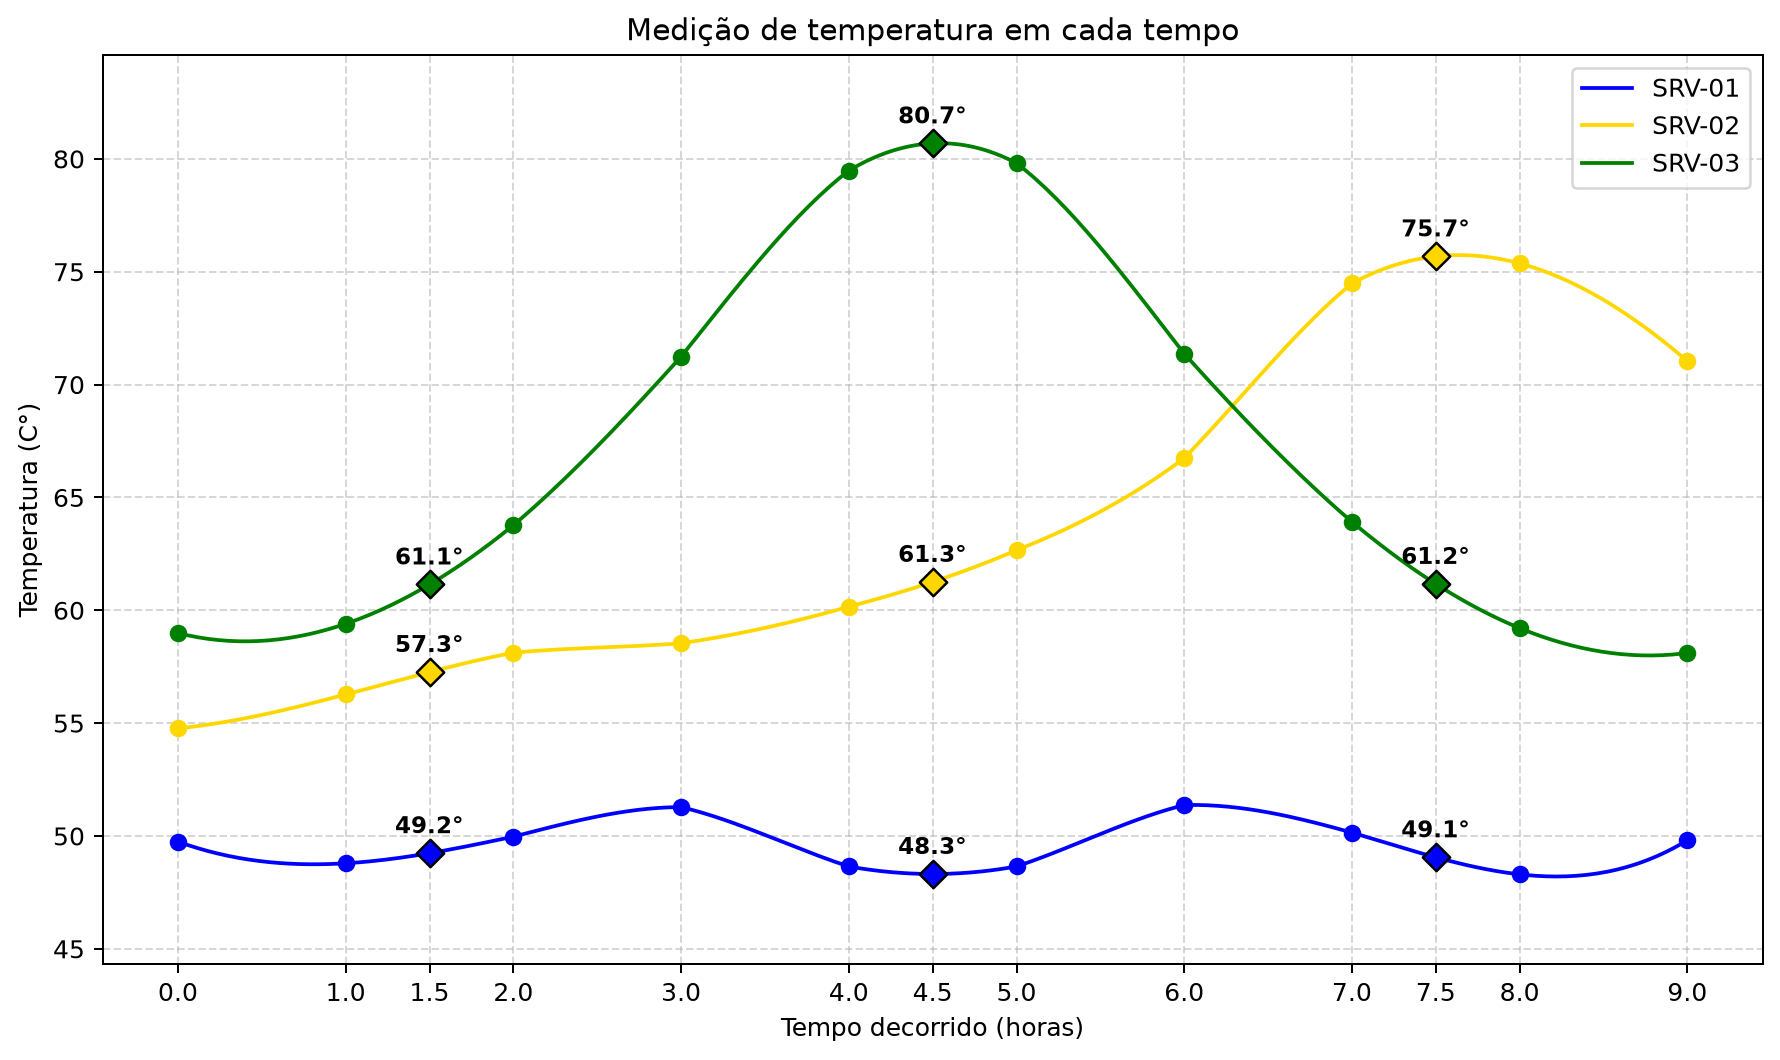

In [2]:
momentos_destaque = sorted(list({inc["t"] for inc in incidentes}))

cores = {
    "SRV-01": "blue",
    "SRV-02": "gold",
    "SRV-03": "green"
}

plt.figure(figsize=(10,6))

for serv, cor in cores.items():
    pontos_orig = pontos_do_servidor(dados_servidores, serv)
    t_orig = [p[0] for p in pontos_orig]
    temp_orig = [p[1] for p in pontos_orig]

    t_curva = np.linspace(min(t_orig), max(t_orig), 300)
    temp_curva = [lagrange_local(pontos_orig, x, 3) for x in t_curva]

    pontos_interp = [p for p in resultados_gerais[serv] if p[0] in momentos_destaque]
    t_interp = [p[0] for p in pontos_interp]
    temp_interp = [p[1] for p in pontos_interp]


    plt.plot(t_curva, temp_curva, color=cor, label=serv, zorder=2)
    plt.scatter(t_orig, temp_orig, color=cor, marker="o", zorder=3)
    plt.scatter(t_interp, temp_interp, color=cor, marker="D", s=60, edgecolor="black", zorder=4)
    for x, y in pontos_interp:
        plt.annotate(
            f"{y:.1f}°",
            (x, y),
            textcoords="offset points",
            xytext=(0, 8),
            ha="center",
            fontsize=9,
            fontweight="bold"
        )


plt.xlabel("Tempo decorrido (horas)")
plt.ylabel("Temperatura (C°)")
plt.title("Medição de temperatura em cada tempo")
plt.grid(True, which='both', ls='--', alpha=0.5)
plt.xticks(sorted(list(range(0, 10)) + momentos_destaque))
plt.margins(y=0.12)
plt.legend()
plt.tight_layout()
plt.show()

### Resposta (d)

Como podemos notar no gráfico, apenas o servidor 3 no momento da medição em que t = 4,5 ou às 18:30, ultrapassa o limite operacional de 80 °C. Sendo assim a provável causa de degradação de desempenho no segundo incidente.